In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import HumSpectra.math_stat as Hst

In [54]:
data = pd.read_excel(r'D:\KNP v2 2024\Data\data_descriptors.xlsx')

data = data[data["sample class"] != "SL2"]
data = data[data["sample name"] != "ADOM-SL3-9"]

data_pH_eH = pd.read_csv(r'D:\KNP v2 2024\Data\data_pH_EH_map.csv')
data_pH_eH.rename(columns={"EH":"eH"},inplace=True)


data = data.merge(data_pH_eH[["sample name","pH","eH"]], on="sample name",how="inner")
feature_columns = ["asm 280","asm 350","E2_E3","SUVA254"]
target_columns = ["pH","eH"]

data.set_index(["sample class","sample name"],inplace=True)
data = Hst.delete_eject_iqr(data,iqr_param=3,columns=["SUVA254","E2_E3"],multi_index=True)

data

genesis class   asm 350   asm 280  blue shift area  \
sample class sample name                                                      
SL3          ADOM-SL3-1           ADOM  4.585517  0.739585        35.821325   
             ADOM-SL3-10          ADOM  4.181767  0.610960        37.684414   
             ADOM-SL3-11          ADOM  4.050084  0.589356        36.773805   
             ADOM-SL3-3           ADOM  4.975271  0.789362        36.098888   
             ADOM-SL3-4           ADOM  4.599892  0.698210        36.659097   
             ADOM-SL3-6           ADOM  4.515299  0.690267        33.733160   
             ADOM-SL3-7           ADOM  3.637584  0.585905        38.720436   
             ADOM-SL3-8           ADOM  3.880215  0.546906        37.250314   
SL4          ADOM-SL4-3           ADOM  4.902269  0.922991        35.591601   
             ADOM-SL4-4           ADOM  4.882618  0.731252        35.768544   
             ADOM-SL4-5           ADOM  4.957161  0.761798        35.784937   
             ADOM-SL4-6           ADOM  4.810555  0.998094        35.272408   
             ADOM-SL4-7           ADOM  4.185304  0.875529        35.002994   
             ADOM-SL4-8           ADOM  4.037838  0.779979        35.186818   
             ADOM-SL4-9           ADOM  4.521705  0.799048        35.320203   
SL5          ADOM-SL5-1           ADOM  4.871496  1.300196        38.561036   
             ADOM-SL5-10          ADOM  4.542279  0.741155        37.107832   
             ADOM-SL5-11          ADOM  4.780582  0.747157        37.632692   
             ADOM-SL5-12          ADOM  4.653677  0.777759        37.118789   
             ADOM-SL5-13          ADOM  4.725792  1.044950        37.422244   
             ADOM-SL5-14          ADOM  4.782334  0.979859        42.606360   
             ADOM-SL5-15          ADOM  4.795653  0.896478        40.107234   
             ADOM-SL5-2           ADOM  5.366813  1.219919        39.896282   
             ADOM-SL5-3           ADOM  4.745260  1.199484        37.968550   
             ADOM-SL5-4           ADOM  4.650357  1.048952        35.108904   
             ADOM-SL5-5           ADOM  4.729903  0.858275        35.286453   
             ADOM-SL5-6           ADOM  4.582089  0.739220        36.049768   
             ADOM-SL5-7           ADOM  4.344675  0.819660        37.483355   
             ADOM-SL5-8           ADOM  4.477541  0.734373        37.855333   
             ADOM-SL5-9           ADOM  4.247980  0.859928        34.081037   
SL6          ADOM-SL6-1           ADOM  5.016603  1.024300        36.418907   
             ADOM-SL6-10          ADOM  4.497996  0.538222        35.774276   
             ADOM-SL6-12          ADOM  4.444397  0.600871        34.530858   
             ADOM-SL6-13          ADOM  4.684942  0.735799        35.853575   
             ADOM-SL6-14          ADOM  4.811954  0.769654        31.596328   
             ADOM-SL6-15          ADOM  4.741251  0.774120        37.006955   
             ADOM-SL6-16          ADOM  5.517711  0.649612        29.155649   
             ADOM-SL6-17          ADOM  4.933845  0.812071        37.278422   
             ADOM-SL6-18          ADOM  4.578544  0.714065        36.182006   
             ADOM-SL6-19          ADOM  4.872803  0.875213        34.843776   
             ADOM-SL6-2           ADOM  5.015139  0.916812        35.711193   
             ADOM-SL6-20          ADOM  4.946454  0.948730        34.675711   
             ADOM-SL6-21          ADOM  4.864959  0.994004        36.475821   
             ADOM-SL6-3           ADOM  5.044382  0.848856        36.629878   
             ADOM-SL6-4           ADOM  4.532512  0.733110        38.949166   
             ADOM-SL6-7           ADOM  4.831985  0.875981        37.410356   
             ADOM-SL6-8           ADOM  4.677498  0.636453        37.391532   
             ADOM-SL6-9           ADOM  4.725669  0.602858        35.558586   
SL7          ADOM-SL7-1           ADOM  4.906626  1.499329        38.710961

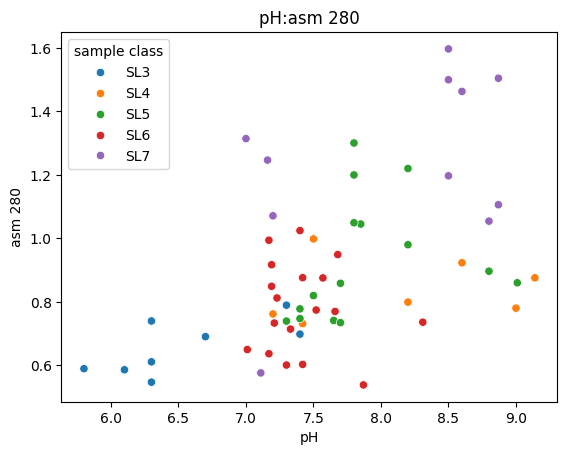

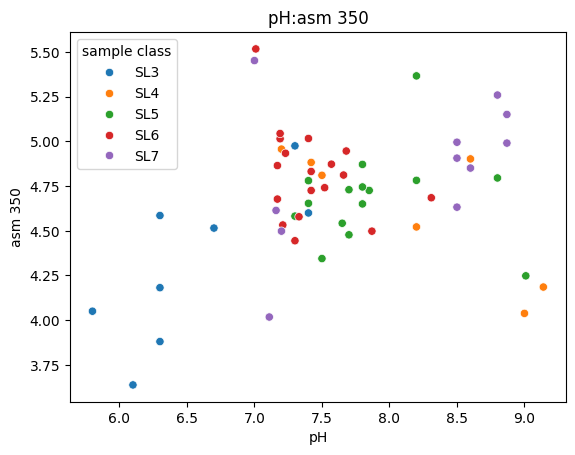

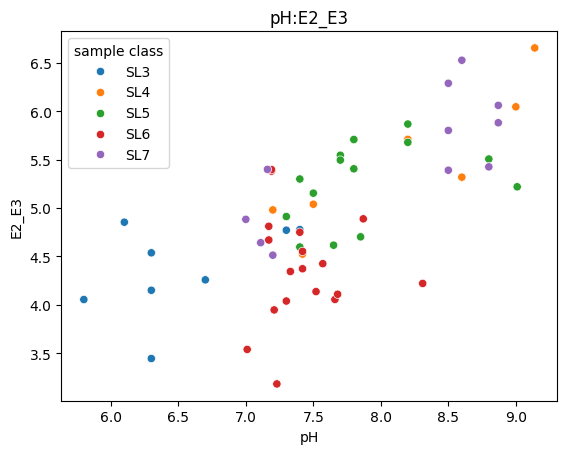

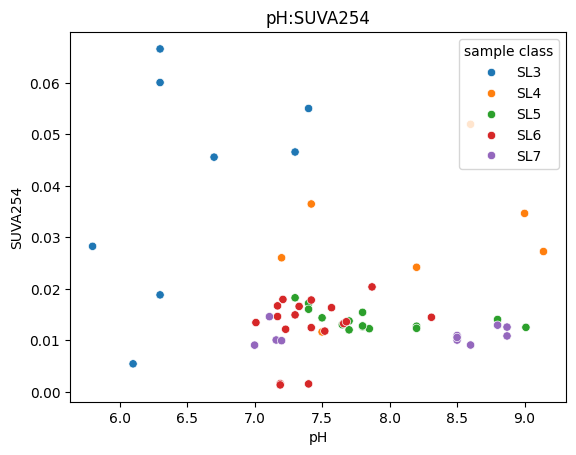

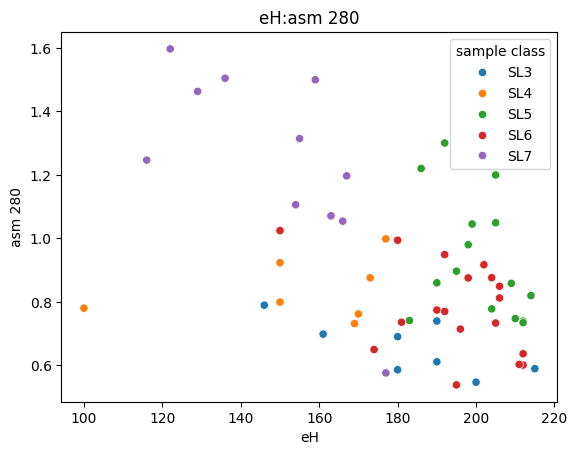

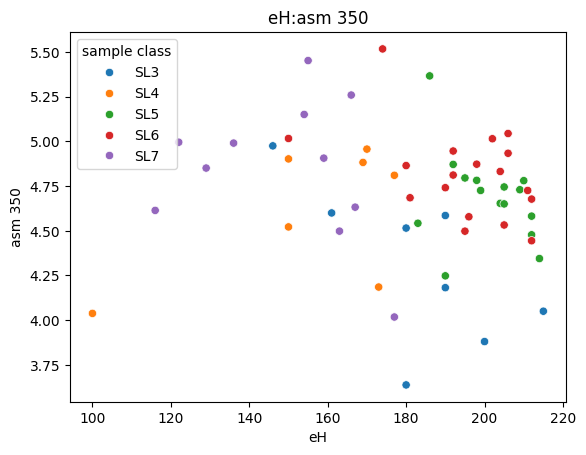

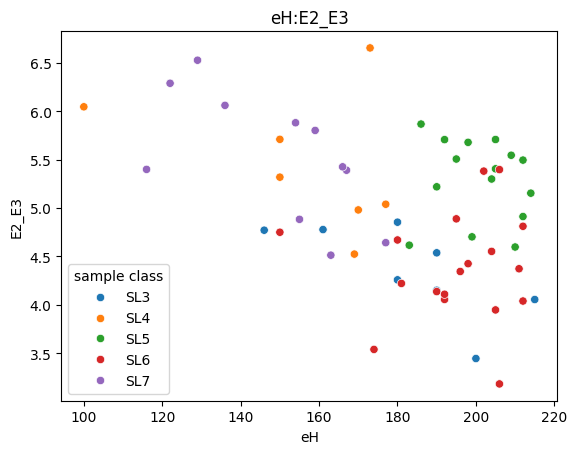

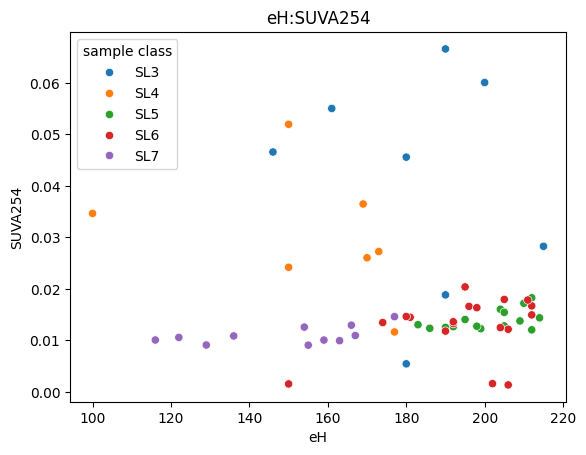

In [42]:
for target in target_columns:

    for feature in feature_columns:
        
        sns.scatterplot(data=data.reset_index(), y=feature,x=target,hue="sample class")
        plt.title(f"{target}:{feature}")
        plt.show()

In [ ]:
data_new = pd.read_excel(r'D:\Solzan\УФ_данные.xlsx')


feature_columns = ["E4/E6","E2/E3","Suva"]
feature_columns_old = ["E4_E6","E2_E3","SUVA254"]
target_columns = ["pH","eH"]

#data_new.set_index(["Class","Sample"],inplace=True)
#data_new = Hst.delete_eject_iqr(data_new,iqr_param=2.5,columns=["Suva"],multi_index=True)

data_new.Class = data_new.reset_index().Sample.apply(lambda x: x.split(sep="-")[0])
data_new

,Class,Sample,E2/E3,E4/E6,lambda,epsilon,Organic C,lattitude,lontitude,pH,eH,Suva
0,K1,K1-10,7.868548,1.499917,0.016439,0.887002,43.000,51.493621,104.234160,7.23,-112.0,0.020628
1,K1,K1-9,5.444303,1.999750,0.011242,0.384002,8.755,51.493861,104.232064,8.48,21.0,0.043861
2,K1,K1-8,4.775196,2.832722,0.014971,0.471002,18.970,51.494003,104.231158,8.90,11.0,0.024829
3,K1,K1-7,5.355858,1.999833,0.009789,0.353001,16.120,51.494359,104.228288,8.89,-10.0,0.021898
4,K1,K1-6,5.054628,1.624766,0.012616,0.404003,15.630,51.494689,104.225789,7.20,-94.0,0.025848
...,...,...,...,...,...,...,...,...,...,...,...,...
87,K9,K9-5,2.661183,1.999667,0.021531,0.183004,4.609,51.490264,104.247637,7.02,110.0,0.039706
88,K9,K9-4,2.893496,1.888593,0.016036,0.152003,4.763,51.490211,104.245922,6.98,143.0,0.031913
89,K9,K9-3,2.847746,1.874781,0.013778,0.145002,5.191,51.490264,104.244545,7.10,140.0,0.027933
90,K9,K9-2,2.804230,1.636190,0.016134,0.143003,5.405,51.493049,104.242800,7.23,173.0,0.026458


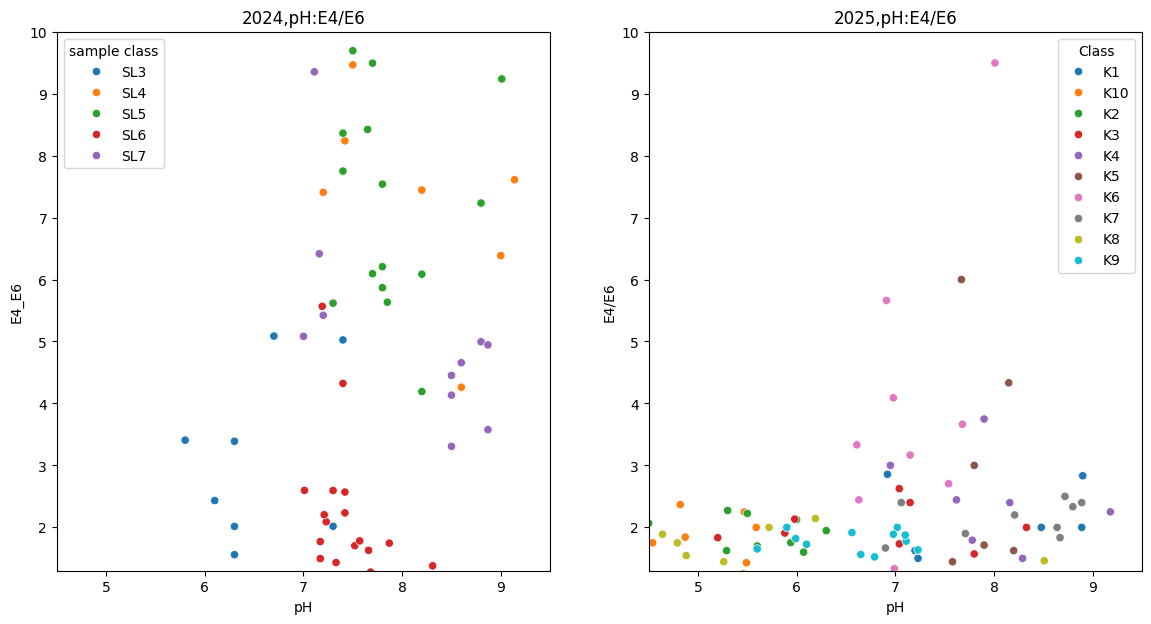

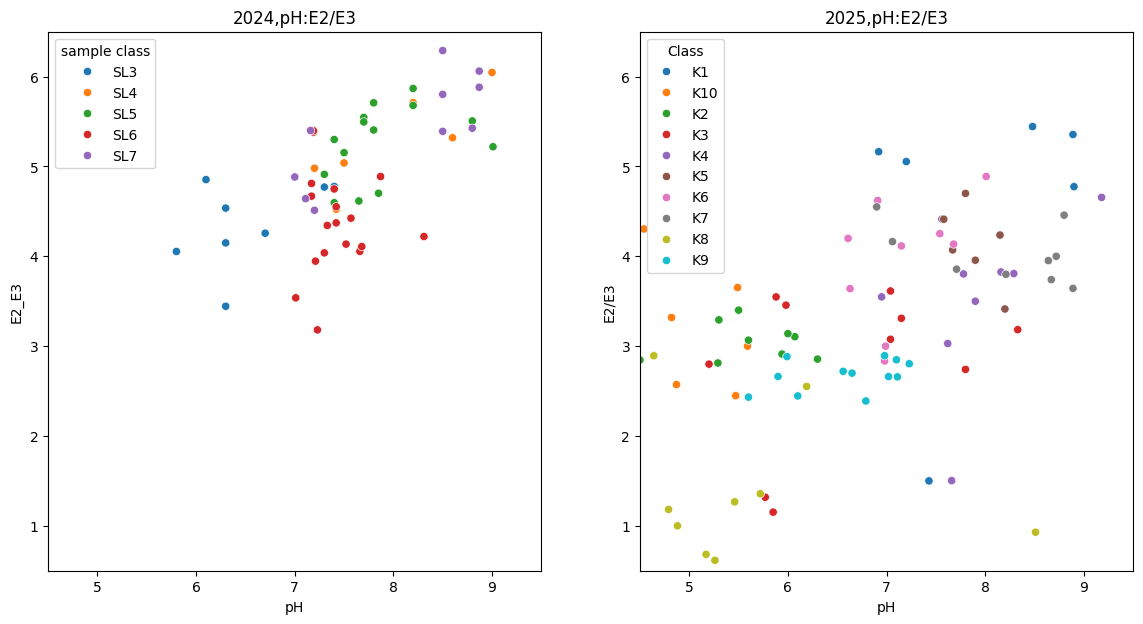

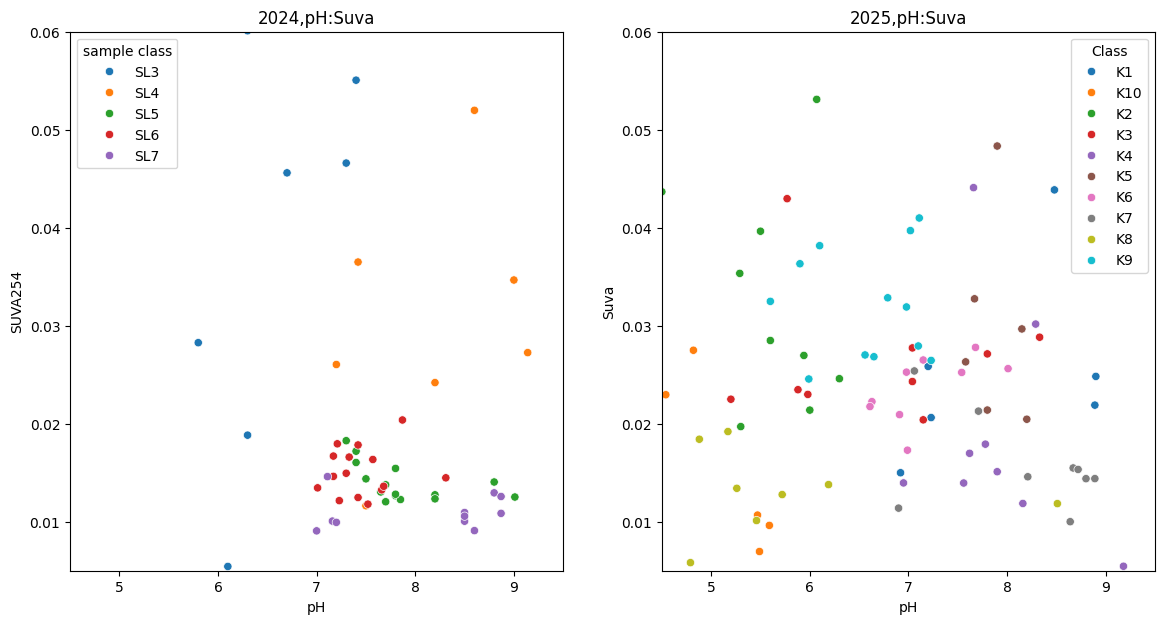

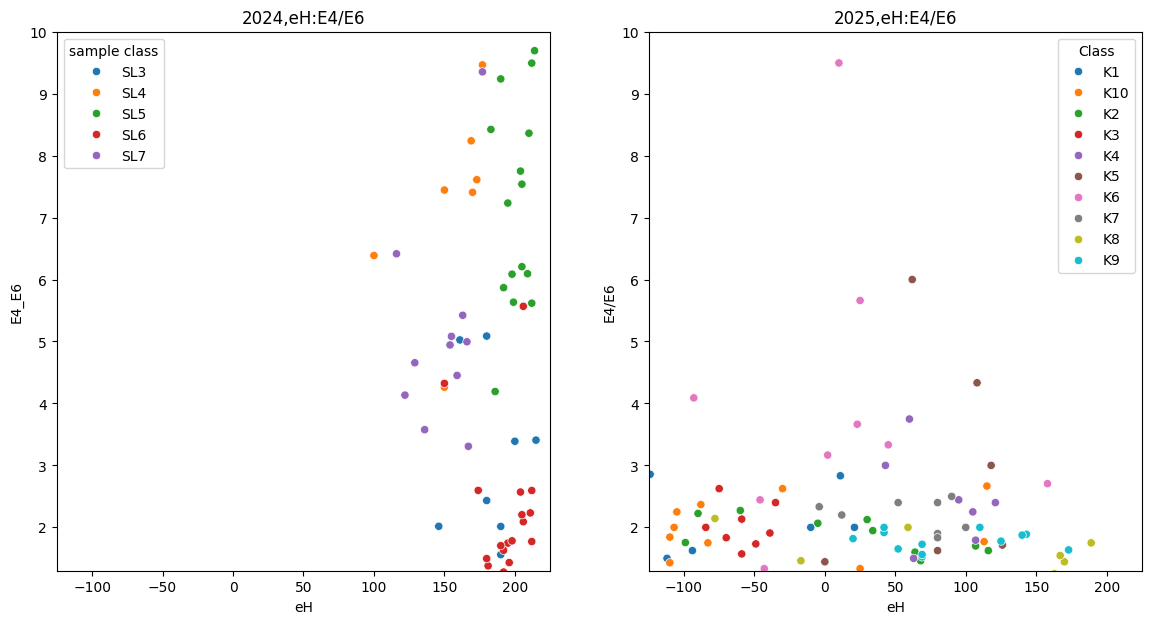

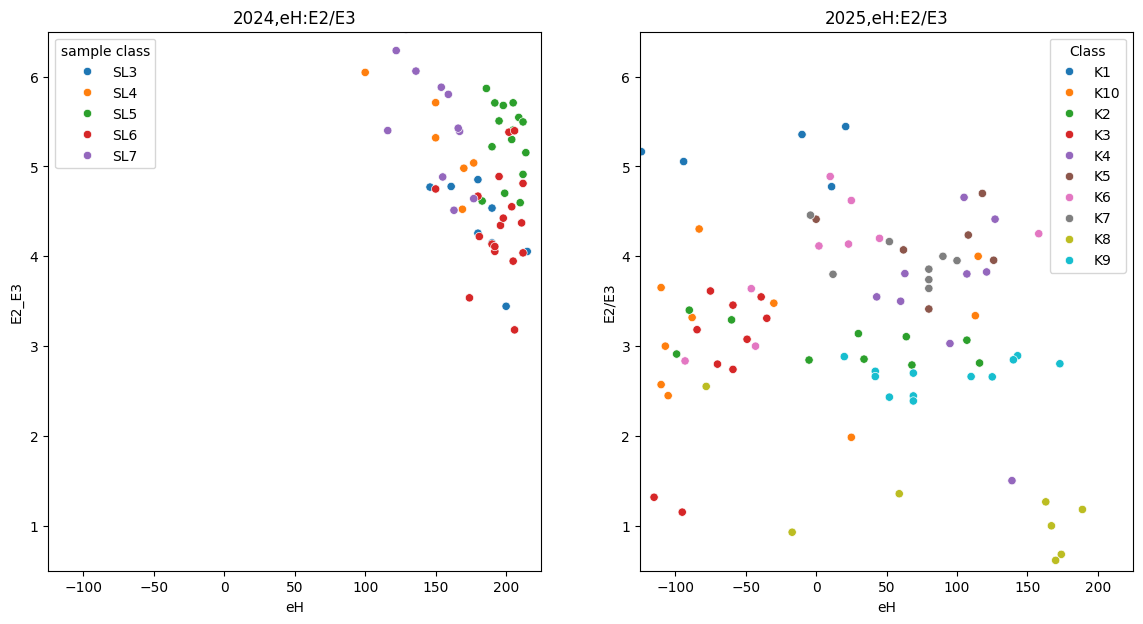

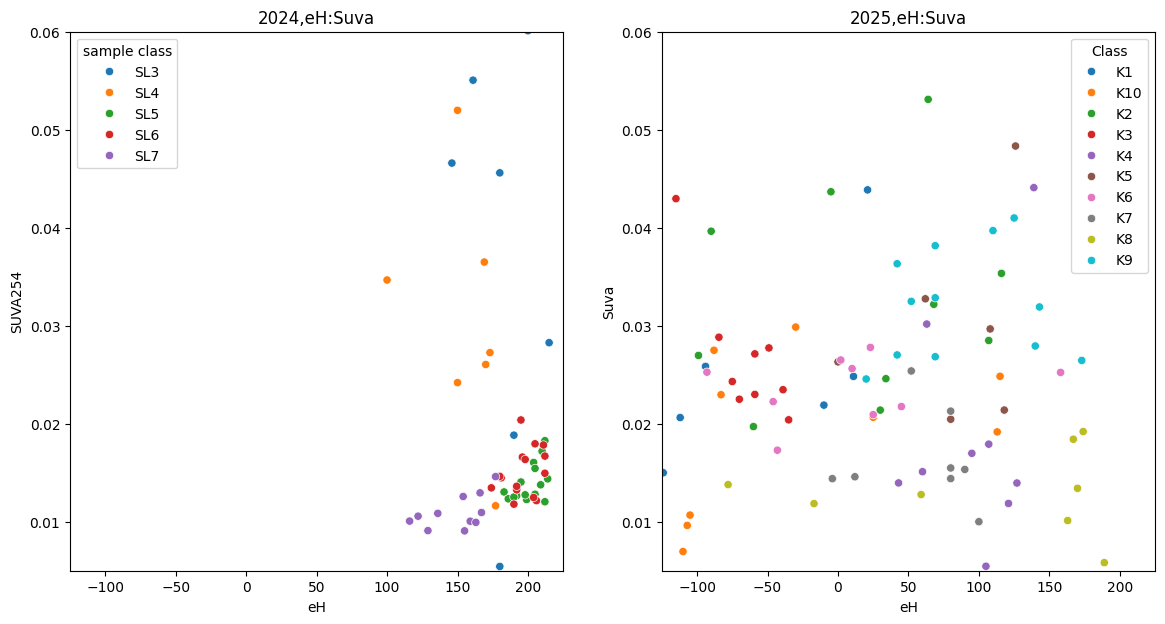

In [76]:
limit_y = [(1.3,10),(0.5,6.5),(0.005,0.06)]
limit_x = [(4.5,9.5),(-125,225)]

for k,target in enumerate(target_columns):

    for i,feature in enumerate(feature_columns):

        fig,ax = plt.subplots(1,2,figsize=(14,7))
        
        sns.scatterplot(data=data.reset_index(), y=feature_columns_old[i],x=target,hue="sample class",ax=ax[0])

        sns.scatterplot(data=data_new.reset_index(), y=feature,x=target,hue="Class",ax=ax[1])
        ax[0].set_title(f"2024,{target}:{feature}")
        ax[1].set_title(f"2025,{target}:{feature}")
        ax[0].set_ylim(limit_y[i])
        ax[0].set_xlim(limit_x[k])
        ax[1].set_ylim(limit_y[i])
        ax[1].set_xlim(limit_x[k])
        plt.show()

In [58]:
data_new["pH"]

0     7.23
1     8.48
2     8.90
3     8.89
4     7.20
      ... 
87    7.02
88    6.98
89    7.10
90    7.23
91    5.99
Name: pH, Length: 92, dtype: float64